In [1]:
import pandas as pd
import keras
import datetime as dt
from datetime import date, timedelta
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np
import tensorflow as tf

In [ ]:
tick = 'AAPL'
today = date.today()
month_ago = today - timedelta(days=60)
roll_out_days = 5
while(month_ago.strftime("%A")!='Monday'):
    month_ago += timedelta(days=1)
TODAY = today.strftime('%Y-%m-%d')
MonthAgo = month_ago.strftime('%Y-%m-%d')
print(TODAY)
print(MonthAgo)

2026-11-14
2026-09-21


In [3]:
def load_data(ticker, START, TODAY):
    data = yf.download(ticker, START, TODAY)
    data.dropna(inplace=True)
    data.columns = data.columns.droplevel(1)
    #data['Target'] = (data['Close'].shift(-1) > data['Close']).astype(int)
    #data = data.drop(['Price','Date'], axis=1)
    data.reset_index(inplace=True)
    return data

In [4]:
data = load_data(tick,MonthAgo, TODAY)
print(data)

[*********************100%***********************]  1 of 1 completed

Price       Date       Close        High         Low        Open    Volume
0     2026-09-21  710.951965  712.248619  704.149449  704.378840   8859800
1     2026-09-22  710.951965  712.468026  710.153968  711.450683  20719800
2     2026-09-23  705.785156  710.552926  704.548346  710.313551  13808900
3     2026-09-24  705.176758  706.772691  701.546079  702.264264   9419700
4     2026-09-25  708.966980  709.824821  704.368818  706.623031   5462300
5     2026-09-28  703.609985  707.330017  701.969971  706.289978   8539400
6     2026-09-29  702.460022  705.000000  700.739990  704.820007   7643300
7     2026-09-30  700.859985  707.200012  700.559998  704.580017   9876100
8     2026-10-01  702.349976  703.729980  697.469971  702.559998   8433700
9     2026-10-02  707.539978  710.200012  705.119995  708.309998   6607300
10    2026-10-05  712.320007  713.859985  707.419983  707.440002   6163600
11    2026-10-06  716.200012  718.469971  715.090027  715.210022   4568400
12    2026-10-07  714.340

In [5]:
data['Day'] = data['Date'].dt.strftime("%A")
df = pd.DataFrame()
i = 0
while i < (len(data)-5):
        df_days = data.iloc[[i]].copy()
        i += 1
        while data.loc[i,'Day'] != 'Monday':
                df_days = pd.concat([df_days,data.iloc[[i]]], ignore_index=True)
                i += 1
        if(len(df_days) == 5):
                df = pd.concat([df, df_days], ignore_index=True)
df = pd.concat([df, data[i:len(data)]], ignore_index=True)
print(df)

Price       Date       Close        High         Low        Open    Volume  \
0     2026-09-21  710.951965  712.248619  704.149449  704.378840   8859800   
1     2026-09-22  710.951965  712.468026  710.153968  711.450683  20719800   
2     2026-09-23  705.785156  710.552926  704.548346  710.313551  13808900   
3     2026-09-24  705.176758  706.772691  701.546079  702.264264   9419700   
4     2026-09-25  708.966980  709.824821  704.368818  706.623031   5462300   
5     2026-09-28  703.609985  707.330017  701.969971  706.289978   8539400   
6     2026-09-29  702.460022  705.000000  700.739990  704.820007   7643300   
7     2026-09-30  700.859985  707.200012  700.559998  704.580017   9876100   
8     2026-10-01  702.349976  703.729980  697.469971  702.559998   8433700   
9     2026-10-02  707.539978  710.200012  705.119995  708.309998   6607300   
10    2026-10-05  712.320007  713.859985  707.419983  707.440002   6163600   
11    2026-10-06  716.200012  718.469971  715.090027  715.210022

In [6]:
df = df.tail(30)
#df = df.drop(columns = ['Volume'])
df = df.reset_index(drop=True)
print(df.shape)
print(df)

(30, 7)
Price       Date       Close        High         Low        Open    Volume  \
0     2026-10-05  712.320007  713.859985  707.419983  707.440002   6163600   
1     2026-10-06  716.200012  718.469971  715.090027  715.210022   4568400   
2     2026-10-07  714.340027  715.059998  711.059998  713.059998   4666900   
3     2026-10-08  711.280029  714.270020  708.159973  712.250000   4763300   
4     2026-10-09  715.590027  716.440002  712.539978  713.539978   4341800   
5     2026-10-12  715.130005  716.419983  714.260010  715.809998   3635500   
6     2026-10-13  715.200012  715.840027  713.270020  714.539978   4950800   
7     2026-10-14  707.429993  713.619995  704.760010  712.320007   6228200   
8     2026-10-15  709.429993  710.400024  702.690002  704.330017   6035500   
9     2026-10-16  701.609985  710.849976  699.190002  710.750000   6095700   
10    2026-10-19  704.599976  708.169983  703.979980  705.270020   5581900   
11    2026-10-20  706.799988  709.809998  702.489990  70

In [7]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [8]:
df_close = df[['Close']].values
df_close

array([[712.32000732],
       [716.20001221],
       [714.34002686],
       [711.2800293 ],
       [715.59002686],
       [715.13000488],
       [715.20001221],
       [707.42999268],
       [709.42999268],
       [701.60998535],
       [704.59997559],
       [706.79998779],
       [710.7199707 ],
       [702.29998779],
       [698.58001709],
       [703.40997314],
       [707.52001953],
       [709.90002441],
       [707.32000732],
       [694.80999756],
       [691.32000732],
       [693.53997803],
       [704.7800293 ],
       [673.9699707 ],
       [675.98999023],
       [691.86999512],
       [689.5       ],
       [698.34997559],
       [696.        ],
       [693.38000488]])

In [9]:
norm_array = scaler.fit_transform(df_close)
norm_array.shape

(30, 1)

In [10]:
train = norm_array[:20]
test = norm_array[20:]
print(train.shape)
print(test.shape)

(20, 1)
(10, 1)


In [11]:
trainX = []
trainY = []
for i in range(roll_out_days, len(train)):
    trainX.append(train[i-roll_out_days: i])
    trainY.append(train[i,0])
trainX, trainY = np.array(trainX), np.array(trainY)


In [12]:
#base_model = keras.models.load_model(tick+'_model.keras')
base_model = keras.models.load_model('model.keras')
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 15)          │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20)             │         2,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,765 (45.96 KB)

 Trainable params: 3,921 (15.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,844 (30.64 KB)

In [13]:
for layer in base_model.layers[:-1]:
    layer.trainable = False

In [14]:
#Recomplie and train the top layer on new data
base_model.compile(optimizer = 'adam', loss='mean_absolute_error',metrics=[tf.keras.metrics.MeanAbsoluteError()])
base_model.fit(trainX, trainY, epochs=30, validation_split =0.2)

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 0.1768 - mean_absolute_error: 0.1768 - val_loss: 0.1692 - val_mean_absolute_error: 0.1692
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1713 - mean_absolute_error: 0.1713 - val_loss: 0.1698 - val_mean_absolute_error: 0.1698
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.1386 - mean_absolute_error: 0.1386 - val_loss: 0.1705 - val_mean_absolute_error: 0.1705
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1830 - mean_absolute_error: 0.1830 - val_loss: 0.1708 - val_mean_absolute_error: 0.1708
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1595 - mean_absolute_error: 0.1595 - val_loss: 0.1709 - val_mean_absolute_error: 0.1709
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.2520 - mean_absolute_error: 0.2520 - val_loss: 0.1709 - val_mean_absolute_error: 0.1709
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.2056 - mean_absolute_error: 0.2056 - val_loss: 0.1709 - val_m

In [15]:
#Unfreeze all layers and fine-tune with a tiny learning rate
for layer in base_model.layers:
    layer.trainable = True

In [16]:
base_model.compile(optimizer = 'adam', loss='mean_absolute_error',metrics=[tf.keras.metrics.MeanAbsoluteError()])
base_model.fit(trainX, trainY, epochs=30, validation_split=0.2)

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 0.1826 - mean_absolute_error: 0.1826 - val_loss: 0.1771 - val_mean_absolute_error: 0.1771
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1553 - mean_absolute_error: 0.1553 - val_loss: 0.1766 - val_mean_absolute_error: 0.1766
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1600 - mean_absolute_error: 0.1600 - val_loss: 0.1777 - val_mean_absolute_error: 0.1777
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.1931 - mean_absolute_error: 0.1931 - val_loss: 0.1745 - val_mean_absolute_error: 0.1745
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.1167 - mean_absolute_error: 0.1167 - val_loss: 0.1697 - val_mean_absolute_error: 0.1697
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.2242 - mean_absolute_error: 0.2242 - val_loss: 0.1651 - val_mean_absolute_error: 0.1651
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.2605 - mean_absolute_error: 0.2605 - val_loss: 0.1627 - val_m

In [17]:
testX = []
testY = []
for i in range(roll_out_days, len(test)):
    testX.append(test[i-roll_out_days:i])
    testY.append(test[i,0])
testX, testY = np.array(testX), np.array(testY)

In [18]:
testX

array([[[0.41084583],
        [0.46341435],
        [0.7295768 ],
        [0.        ],
        [0.04783371]],

       [[0.46341435],
        [0.7295768 ],
        [0.        ],
        [0.04783371],
        [0.42386945]],

       [[0.7295768 ],
        [0.        ],
        [0.04783371],
        [0.42386945],
        [0.36774838]],

       [[0.        ],
        [0.04783371],
        [0.42386945],
        [0.36774838],
        [0.57731425]],

       [[0.04783371],
        [0.42386945],
        [0.36774838],
        [0.57731425],
        [0.52166724]]])

In [19]:
testY

array([0.42386945, 0.36774838, 0.57731425, 0.52166724, 0.45962622])

In [20]:
y_pred = base_model.predict(testX)
len(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step


5

In [21]:
y_pred

array([[0.38174185],
       [0.33988544],
       [0.30090073],
       [0.2675636 ],
       [0.36516023]], dtype=float32)

In [22]:
# Total predict
total_testX = []
total_testY = []
for i in range(roll_out_days, len(norm_array)):
    total_testX.append(norm_array[i-roll_out_days:i])
    total_testY.append(norm_array[i,0])
total_testX, total_testY = np.array(total_testX), np.array(total_testY)

In [23]:
total_pred = base_model.predict(total_testX)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step


In [24]:
#future 5days value
new_pred = y_pred[-1]
new_arr = testX[-1]
l_pred = []
for i in range(0, roll_out_days):
    new_pred = new_pred.item()
    new_arr = new_arr[1:roll_out_days]
    new_arr = np.append(new_arr,new_pred)
    new_arr = new_arr.reshape(1,5,1)
    new_pred = base_model.predict(new_arr)
    new_arr = new_arr.reshape(5,1)
    l_pred.append([new_pred[-1].item()])
l_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


[[0.45204469561576843],
 [0.4536430239677429],
 [0.46129265427589417],
 [0.4428861141204834],
 [0.4405052363872528]]

In [25]:
new_y_pred = np.concatenate((total_pred, l_pred))
len(new_y_pred)

30

In [26]:
final = scaler.inverse_transform(new_y_pred)
final

array([[708.47164913],
       [708.96024469],
       [708.61934539],
       [708.12870845],
       [708.12241065],
       [706.10579544],
       [704.26631406],
       [702.44723886],
       [702.42713473],
       [701.59230863],
       [701.71085177],
       [701.46088798],
       [701.20001253],
       [700.36462008],
       [701.2373538 ],
       [701.6091959 ],
       [699.97001579],
       [697.47047102],
       [696.00390654],
       [692.69245266],
       [690.09094494],
       [688.32334709],
       [686.67702091],
       [685.26919311],
       [689.39070224],
       [693.05983696],
       [693.12733443],
       [693.45037864],
       [692.67306968],
       [692.57252512]])

In [27]:
print(df.shape)
print(df)

(30, 7)
Price       Date       Close        High         Low        Open    Volume  \
0     2026-10-05  712.320007  713.859985  707.419983  707.440002   6163600   
1     2026-10-06  716.200012  718.469971  715.090027  715.210022   4568400   
2     2026-10-07  714.340027  715.059998  711.059998  713.059998   4666900   
3     2026-10-08  711.280029  714.270020  708.159973  712.250000   4763300   
4     2026-10-09  715.590027  716.440002  712.539978  713.539978   4341800   
5     2026-10-12  715.130005  716.419983  714.260010  715.809998   3635500   
6     2026-10-13  715.200012  715.840027  713.270020  714.539978   4950800   
7     2026-10-14  707.429993  713.619995  704.760010  712.320007   6228200   
8     2026-10-15  709.429993  710.400024  702.690002  704.330017   6035500   
9     2026-10-16  701.609985  710.849976  699.190002  710.750000   6095700   
10    2026-10-19  704.599976  708.169983  703.979980  705.270020   5581900   
11    2026-10-20  706.799988  709.809998  702.489990  70

In [28]:
df_result = df[['Date','Close']]
df_result

Price,Date,Close
0,2026-10-05,712.320007
1,2026-10-06,716.200012
2,2026-10-07,714.340027
3,2026-10-08,711.280029
4,2026-10-09,715.590027
5,2026-10-12,715.130005
6,2026-10-13,715.200012
7,2026-10-14,707.429993
8,2026-10-15,709.429993
9,2026-10-16,701.609985


In [29]:
df_final = df_result[6:]
df_final = df_final.reset_index(drop = True)
max_day = df_final['Date'].max().strftime('%Y-%m-%d')
more_day = (df_final['Date'].max()+timedelta(days=roll_out_days)).strftime('%Y-%m-%d')
#print(df_final['Date'].max())
#print(df_final['Date'].max()+timedelta(days=5))
dates = pd.date_range(start=max_day, end=more_day, freq='D')
df_extra = pd.DataFrame({'Date': dates, 'Close':np.nan, 'Pred':np.nan})
df_final = pd.concat([df_final,df_extra], ignore_index=True)
print(len(final))
print(df_final.shape)
df_final['Pred'] = final
print(df_final)

30
(30, 3)
         Date       Close        Pred
0  2026-10-13  715.200012  708.471649
1  2026-10-14  707.429993  708.960245
2  2026-10-15  709.429993  708.619345
3  2026-10-16  701.609985  708.128708
4  2026-10-19  704.599976  708.122411
5  2026-10-20  706.799988  706.105795
6  2026-10-21  710.719971  704.266314
7  2026-10-22  702.299988  702.447239
8  2026-10-23  698.580017  702.427135
9  2026-10-26  703.409973  701.592309
10 2026-10-27  707.520020  701.710852
11 2026-10-28  709.900024  701.460888
12 2026-10-29  707.320007  701.200013
13 2026-10-30  694.809998  700.364620
14 2026-11-02  691.320007  701.237354
15 2026-11-03  693.539978  701.609196
16 2026-11-04  704.780029  699.970016
17 2026-11-05  673.969971  697.470471
18 2026-11-06  675.989990  696.003907
19 2026-11-09  691.869995  692.692453
20 2026-11-10  689.500000  690.090945
21 2026-11-11  698.349976  688.323347
22 2026-11-12  696.000000  686.677021
23 2026-11-13  693.380005  685.269193
24 2026-11-13         NaN  689.390702
2

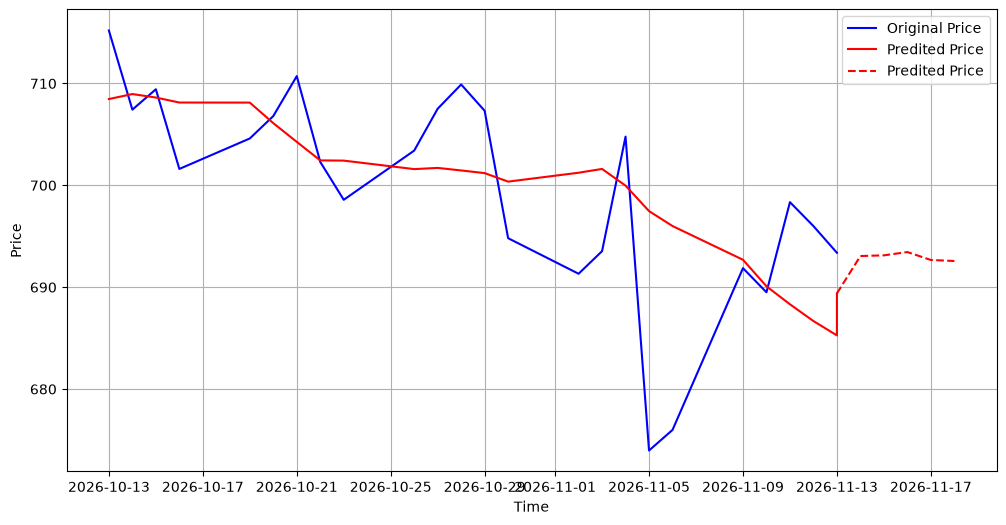

In [30]:
plt.figure(figsize = (12,6))
plt.plot('Date','Close',data = df_final, color='b', label = 'Original Price')
plt.plot('Date','Pred',data = df_final[:25], color='r', label = 'Predited Price')
plt.plot('Date','Pred',data = df_final[24:], linestyle='--', color='r', label = 'Predited Price')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Model evaluation
from sklearn.metrics import mean_absolute_error
mean = mean_absolute_error(total_testY, total_pred)
mean_percentage=(mean / np.mean(total_testY)) * 100
print('Mean absolute error on test set: {:.2f}%'.format(mean_percentage))

Mean absolute error on test set: 24.35%


In [32]:
from sklearn.metrics import r2_score
r2 = r2_score(total_testY, total_pred)
print('R2 score: ',r2)

R2 score:  0.3806652109629437
